# Reduction of ESTIA McStas data

- Audience: Instrument users, beginners
- Prerequisites: Basic knowledge of [Scipp](https://scipp.github.io/)

This notebook demonstrates the basic reflectometry data reduction workflow for ESTIA with simulated data.
A workflow for data recorded at ESS would be very similar but is not yet available.
The workflow:

1. Converts the data to momentum transfer $Q$.
2. Normalizes by a reference measurement.
3. Packages the results to be saved to an [ORSO ORT](https://www.reflectometry.org/advanced_and_expert_level/file_format) file.

The data is available through the ESSreflectometry package but accessing it requires the pooch package.
If you get an error about a missing module pooch, you can install it with `!pip install pooch`.

In [1]:
import plopp as pp
import scipp as sc

from ess.estia import data
from ess.estia import EstiaMcStasWorkflow
from ess.reflectometry.types import *

## Create and configure the workflow

We begin by creating the ESTIA (McStas) workflow object which is a skeleton for reducing ESTIA data with pre-configured steps:

In [2]:
wf = EstiaMcStasWorkflow()

We then need to set the missing parameters which are specific to each experiment (the keys are types defined in [ess.reflectometry.types](../../generated/modules/ess.reflectometry.types.rst)).

In [3]:
# Specify input data files:
# (The choice of 'Ni/Ti-multilayer' file number 3 is arbitrary.)
wf[Filename[SampleRun]] = data.estia_mcstas_sample_example('Ni/Ti-multilayer')[3]
wf[Filename[ReferenceRun]] = data.estia_mcstas_reference_example()

# Select a region of interest:
wf[YIndexLimits] = sc.scalar(35), sc.scalar(64)
wf[ZIndexLimits] = sc.scalar(0), sc.scalar(48 * 32)
wf[BeamDivergenceLimits] = sc.scalar(-0.75, unit='deg'), sc.scalar(0.75, unit='deg')

# Configure the binning of intermediate and final results:
wf[WavelengthBins] = sc.geomspace('wavelength', 3.5, 12, 401, unit='angstrom')
wf[QBins] = 400

wf[LookupTableFilename] = data.estia_wavelength_lookup_table()

We can visualize the workflow as a graph.
This can help us understand how the data will be reduced.
(`ReflectivityOverQ` is the key of the output data.)

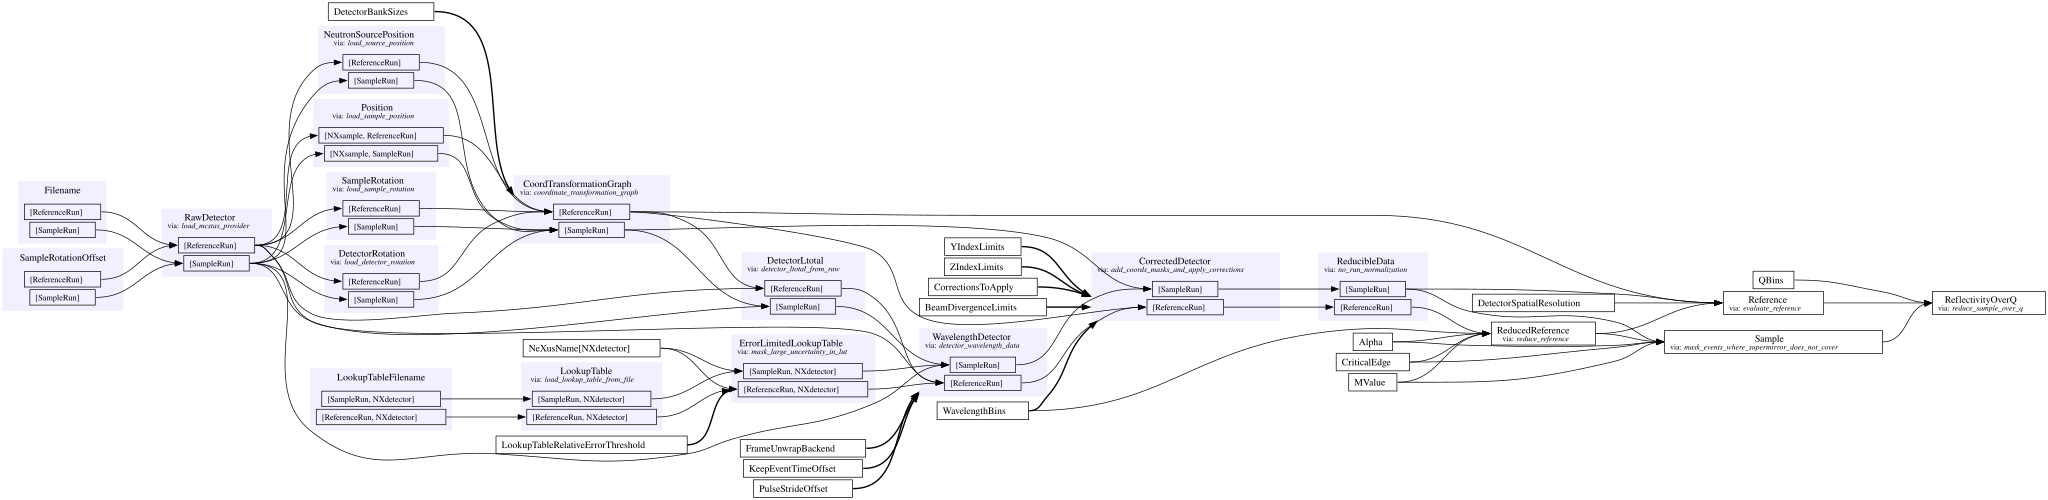

In [4]:
wf.visualize(ReflectivityOverQ, graph_attr={'rankdir': "LR"})

The workflow is a [Sciline](https://scipp.github.io/sciline/) pipeline.
See the documentation of Sciline for more information and how to modify and extend the workflow.

## Use the reduction workflow

We call [wf.compute(targets)](https://scipp.github.io/sciline/generated/classes/sciline.Pipeline.html#sciline.Pipeline.compute) to compute the result:

In [5]:
reflectivity = wf.compute(ReflectivityOverQ)

The reflectivity is still event data.
We can histogram it and plot it:

/home/runner/work/ess/ess/.pixi/envs/docs-essreflectometry/lib/python3.12/site-packages/matplotlib/axes/_axes.py:4238: RuntimeWarning: invalid value encountered in add
  low, high = dep + np.vstack([-(1 - lolims), 1 - uplims]) * err


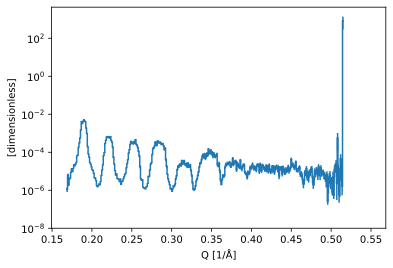

In [6]:
measured = reflectivity.hist()
pp.plot(measured, logy=True, ymin=1e-8)

## Compare with the ground truth

For this simulated sample, we know the ideal reflectivity. Smoothing it with the instrument resolution lets us compare it with the reduced data.

The helper uses an approximate trapezoidal response with a 60% plateau, scaled so its standard deviation matches `Q_resolution`.
It requires [Refl1D](https://refl1d.readthedocs.io/en/stable/_modules/refl1d/sample/reflectivity.html), which you can install with `%pip install refl1d`.

In [7]:
from ess.reflectometry.tools import smooth_with_resolution

ground_truth = data.estia_mcstas_groundtruth('Ni/Ti-multilayer')
smoothed_ground_truth = smooth_with_resolution(ground_truth, measured)

Smoothing rounds peaks and fills minima. The prediction is evaluated at $Q$-bin centres without including bin-width effects, so choose bins much narrower than the resolution.

Weak reference intensity can make the edges noisy; see the [advanced notebook](./estia-advanced-mcstas-reduction.ipynb) for masking.

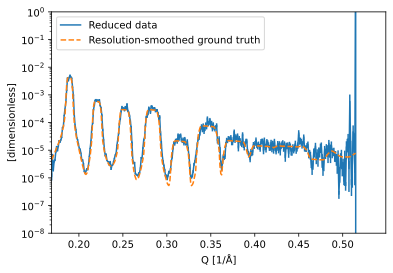

In [8]:
# Exclude undefined intensities and error bars from the display.
finite_data = sc.isfinite(measured.data) & sc.isfinite(sc.variances(measured.data))
measured_plot = measured.assign_coords(Q=smoothed_ground_truth.coords['Q'])[finite_data]

pp.plot(
    {
        'Reduced data': measured_plot,
        'Resolution-smoothed ground truth': smoothed_ground_truth,
    },
    logy=True,
    ymin=1e-8,
    ymax=1.0,
    xmin=measured_plot.coords['Q'].min(),
    xmax=measured_plot.coords['Q'].max(),
    ls={'Reduced data': 'solid', 'Resolution-smoothed ground truth': 'dashed'},
    marker='none',
)

## Saving to ORSO ORT file

Ultimately, we want to save the reduced data to a file.
The workflow supports building an [ORSO dataset](https://www.reflectometry.org/orsopy/orsopy.fileio.html#orsopy.fileio.OrsoDataset) from the reduced data: `OrsoIofQDataset`.
We require some additional imports:

In [9]:
from orsopy import fileio

from ess.reflectometry import orso

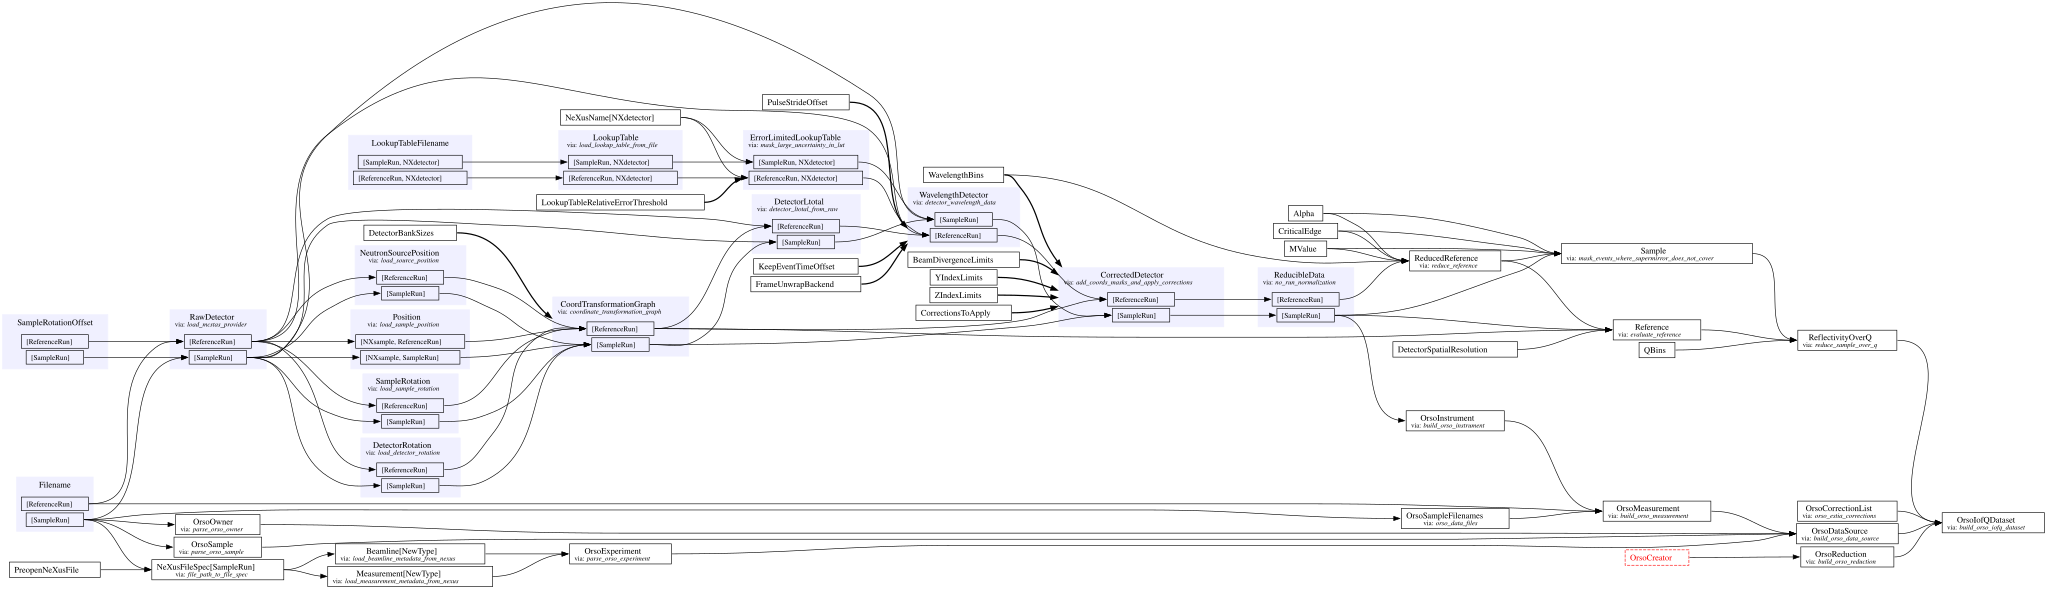

In [10]:
wf.visualize(orso.OrsoIofQDataset, graph_attr={'rankdir': "LR"})

We can see from the graph that some nodes are missing (red boxes).
These need to be manually provided as they cannot be deduced from the input.
Further, McStas files do not contain all required metadata, so that needs to be provided manually as well.

In [11]:
wf[orso.Beamline] = orso.Beamline(name='ESTIA', facility='ESS')
wf[orso.Measurement] = orso.Measurement(
    title='McStas Simulation, Ni/Ti-multilayer',
)
wf[orso.OrsoSample] = orso.OrsoSample(
    fileio.data_source.Sample(name='Ni/Ti multilayer')
)
wf[orso.OrsoCreator] = orso.OrsoCreator(
    fileio.base.Person(
        name='Max Mustermann',
        affiliation='European Spallation Source ERIC',
        contact='max.mustermann@ess.eu',
    )
)
wf[orso.OrsoOwner] = wf[orso.OrsoCreator]

Now that we have these additional parameters, we can construct the ORSO dataset:
(Note that this will re-run the reduction procedure to ensure that all data is consistent.)

In [12]:
dataset = wf.compute(orso.OrsoIofQDataset)

The `dataset` has not been written to disk yet.
For that, simply call `save`:

In [13]:
dataset.save('estia_reduced_iofq.ort')

---

Next, consider reading the [ESTIA advanced McStas reduction](./estia-advanced-mcstas-reduction.rst) guide, which demonstrates how multiple files can be reduced together and how to make different types of plots.